# Prediksi Suhu Kritis Superkonduktor dengan Machine Learning

Proyek ini menggunakan *machine learning* untuk memprediksi suhu kritis (`critical_temp`, disingkat **Tc**) material superkonduktor dari deskriptor material hasil rekayasa fitur (*engineered descriptors*). Beberapa model regresi dibandingkan, performanya dievaluasi, dan fitur yang paling informatif dianalisis.

## Motivasi

Pada 2026, banjir besar melanda Dagestan, Rusia. Pejabat setempat menyebut sebagian kerusakan infrastruktur disebabkan oleh kabel listrik yang menua: aus, terlalu panas, lalu gagal saat tertekan.

Kejadian itu memunculkan satu pertanyaan: bagaimana kalau jaringan listrik tidak kehilangan energi sama sekali?

Superkonduktor, yaitu material yang menghantarkan listrik **tanpa hambatan**, bisa jadi jawabannya. Material ini tidak panas berlebih dan tidak menua dengan cara yang sama, sehingga bisa membuat infrastruktur listrik jauh lebih andal. Masalahnya, kebanyakan superkonduktor baru bekerja pada suhu yang sangat rendah, sehingga belum praktis dipakai.

Menemukan material dengan suhu kritis (Tc) tinggi, yaitu suhu di bawah mana superkonduktivitas muncul, adalah salah satu masalah terbuka terpenting di fisika modern dan ilmu material. Proyek ini memakai ML untuk memprediksi Tc dari deskriptor material, sebagai langkah awal membangun *pipeline* penyaringan (*screening*) kandidat superkonduktor.

## Perubahan dari versi sebelumnya

| Masalah di versi lama | Perbaikan di versi ini |
|---|---|
| Path data hanya jalan di Kaggle (`/kaggle/input/...`) | Otomatis mencari file di beberapa lokasi (Kaggle, Colab, folder lokal) dan mengunduh dari UCI bila tidak ada |
| `engine="python"` saat membaca CSV (lambat) | Memakai *engine* C yang jauh lebih cepat, dengan *fallback* otomatis |
| Hanya kolom `wtd_std_Density` yang dibersihkan | Semua kolom dipaksa numerik, lalu baris tidak valid dibuang, dengan laporan jumlah baris yang dibuang |
| `GradientBoostingRegressor` + CV 5-lipat + RF 300 pohon (lama) | `HistGradientBoostingRegressor`, RF 100 pohon, CV 3-lipat, XGBoost mode `hist` |
| Kode training berulang untuk tiap model | Satu fungsi `latih_dan_evaluasi()` untuk semua model, plus catatan waktu |
| `xgboost` bisa belum terpasang, notebook langsung error | Dicoba pasang otomatis; jika gagal, model XGBoost dilewati tanpa error |
| Tidak ada demo | Demo input/output: prediksi sampel, input manual, peringkat kandidat, simpan/muat model |

**Perkiraan waktu jalan:** sekitar 2 sampai 5 menit pada Kaggle/Colab untuk data penuh (21.263 baris). Jika ingin lebih cepat lagi, ubah `JALANKAN_CV = False` di sel pengaturan.

## 1. Persiapan dan Pengaturan

Sel di bawah mengimpor pustaka dan menyimpan pengaturan utama. Anda cukup mengubah nilai di sini jika perlu.

In [1]:
import os
import sys
import time
import zipfile
import subprocess
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")   # sembunyikan peringatan yang tidak penting

# XGBoost: jika belum terpasang, coba pasang otomatis. Kalau gagal, model ini dilewati.
try:
    from xgboost import XGBRegressor
    ADA_XGBOOST = True
except ImportError:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
        from xgboost import XGBRegressor
        ADA_XGBOOST = True
    except Exception:
        ADA_XGBOOST = False
        print("XGBoost tidak bisa dipasang, model XGBoost akan dilewati.")

# ===================== PENGATURAN =====================
SEED = 42                        # angka acak tetap agar hasil bisa diulang
CV_LIPAT = 3                     # jumlah lipatan cross-validation (3 = cepat, 5 = lebih teliti)
JALANKAN_CV = True               # False = lewati cross-validation agar lebih cepat
GUNAKAN_DATA_SINTETIS = False    # True hanya untuk uji coba kode tanpa dataset asli
JUMLAH_DATA_SINTETIS = 3000      # ukuran data sintetis (dipakai jika opsi di atas True)
# ======================================================

plt.rcParams["figure.dpi"] = 100
print("Pengaturan selesai. XGBoost tersedia:", ADA_XGBOOST)

Pengaturan selesai. XGBoost tersedia: True


## 2. Dataset

Dataset berisi deskriptor numerik (hasil rekayasa fitur) dari material superkonduktor dan variabel target `critical_temp`. Versi asli berisi 21.263 material dengan 81 fitur. Fitur-fiturnya berasal dari delapan sifat atom (massa atom, energi ionisasi pertama, jari-jari atom, densitas, afinitas elektron, panas peleburan, konduktivitas termal, valensi) yang diringkas dengan berbagai statistik (rata-rata, rentang, simpangan baku, entropi, dan lainnya).

Sel berikut mencari `train.csv` secara otomatis. Urutannya: (1) lokasi umum di Kaggle/Colab/lokal, (2) unduh dari UCI Machine Learning Repository. Jika keduanya gagal, akan muncul pesan yang jelas tentang cara memperbaikinya.

In [2]:
# Lokasi-lokasi yang dicek untuk file train.csv
KANDIDAT_PATH = [
    "/kaggle/input/datasets/munumbutt/superconductor-dataset/train.csv",  # path lama (Kaggle)
    "/kaggle/input/superconductor-dataset/train.csv",
    "train.csv",                      # satu folder dengan notebook
    "/content/train.csv",             # Google Colab
    "/mnt/user-data/uploads/train.csv",
]
URL_UCI = "https://archive.ics.uci.edu/static/public/464/superconductivty+data.zip"


def baca_csv(path):
    """Baca CSV dengan cepat; jika gagal, ulangi dengan engine python yang lebih toleran."""
    try:
        return pd.read_csv(path, on_bad_lines="skip")
    except Exception:
        return pd.read_csv(path, engine="python", on_bad_lines="skip")


def unduh_dari_uci():
    """Unduh dataset dari UCI lalu ekstrak train.csv. Mengembalikan path file atau None."""
    try:
        print("Mengunduh dataset dari UCI ...")
        urllib.request.urlretrieve(URL_UCI, "superconductivity.zip")
        with zipfile.ZipFile("superconductivity.zip") as z:
            z.extract("train.csv", ".")
        return "train.csv"
    except Exception as e:
        print("Unduhan gagal:", e)
        return None


def buat_data_sintetis(n=3000, seed=42):
    """Data tiruan dengan struktur kolom yang sama. HANYA untuk menguji kode, bukan untuk sains."""
    rng = np.random.default_rng(seed)
    sifat = ["atomic_mass", "fie", "atomic_radius", "Density",
             "ElectronAffinity", "FusionHeat", "ThermalConductivity", "Valence"]
    statistik = ["mean", "wtd_mean", "gmean", "wtd_gmean", "entropy",
                 "wtd_entropy", "range", "wtd_range", "std", "wtd_std"]
    kolom = ["number_of_elements"] + [f"{s}_{p}" for p in sifat for s in statistik]
    data = pd.DataFrame(rng.gamma(2.0, 1.0, (n, len(kolom))), columns=kolom)
    data["number_of_elements"] = rng.integers(1, 9, n)
    tc = (8 * data["range_ThermalConductivity"] + 15 * np.sin(data["wtd_std_ThermalConductivity"])
          + 5 * data["number_of_elements"] - 6 * data["mean_Valence"] + rng.normal(0, 5, n))
    data["critical_temp"] = np.clip(tc, 0.1, None)
    # sengaja disisipi nilai rusak untuk meniru masalah pada kolom wtd_std_Density
    data["wtd_std_Density"] = data["wtd_std_Density"].astype(object)
    data.loc[data.sample(5, random_state=seed).index, "wtd_std_Density"] = "rusak"
    return data


df = None
if GUNAKAN_DATA_SINTETIS:
    df = buat_data_sintetis(JUMLAH_DATA_SINTETIS, SEED)
    print("PERINGATAN: memakai data SINTETIS, hasilnya bukan hasil sains yang sebenarnya.")
else:
    path_data = next((p for p in KANDIDAT_PATH if os.path.exists(p)), None)
    if path_data is None:
        path_data = unduh_dari_uci()
    if path_data is not None:
        print("Membaca data dari:", path_data)
        df = baca_csv(path_data)

if df is None:
    raise FileNotFoundError(
        "File train.csv tidak ditemukan dan unduhan otomatis gagal.\n"
        "Solusi: unduh dataset 'Superconductivty Data' (file train.csv) dari Kaggle atau UCI, "
        "letakkan di folder yang sama dengan notebook ini, lalu jalankan ulang sel ini."
    )

print("Ukuran data mentah:", df.shape)
df.head()

Mengunduh dataset dari UCI ...
Membaca data dari: train.csv
Ukuran data mentah: (21263, 82)


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


## 3. Pembersihan Data (Preprocessing)

Pada data asli, kolom `wtd_std_Density` terbaca sebagai teks karena ada nilai yang tidak valid. Agar aman, **semua** kolom dikonversi ke numerik (nilai yang tidak bisa dikonversi menjadi `NaN`), lalu baris yang mengandung `NaN` dibuang. Setelah itu, target didefinisikan sebagai `critical_temp` dan seluruh kolom lain menjadi fitur masukan.

In [3]:
baris_awal = len(df)

# Paksa semua kolom menjadi angka; nilai yang tidak valid menjadi NaN
df = df.apply(pd.to_numeric, errors="coerce")

# Buang baris yang mengandung NaN, lalu rapikan indeks
df = df.dropna().reset_index(drop=True)

print(f"Baris sebelum dibersihkan : {baris_awal}")
print(f"Baris sesudah dibersihkan : {len(df)}  (dibuang: {baris_awal - len(df)})")

# Pastikan kolom target ada
assert "critical_temp" in df.columns, "Kolom 'critical_temp' tidak ditemukan di dataset."

y = df["critical_temp"]                  # target yang diprediksi (dalam Kelvin)
X = df.drop(columns=["critical_temp"])   # semua kolom lain = fitur

print("Jumlah fitur:", X.shape[1])

Baris sebelum dibersihkan : 21263
Baris sesudah dibersihkan : 21263  (dibuang: 0)
Jumlah fitur: 81


## 4. Pembagian Data Latih dan Uji

Data dibagi menjadi 80% data latih (untuk melatih model) dan 20% data uji (untuk menilai performa pada data yang belum pernah dilihat model).

In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)

Data latih: (17010, 81) | Data uji: (4253, 81)


## 5. Model yang Dibandingkan

Lima model regresi diuji:

- **Linear Regression**: model linear sederhana, sebagai pembanding dasar (*baseline*).
- **Decision Tree**: satu pohon keputusan.
- **Random Forest**: gabungan banyak pohon yang dilatih pada sampel acak.
- **Gradient Boosting (Hist)**: *boosting* berbasis histogram. Hasilnya setara `GradientBoostingRegressor` biasa tetapi jauh lebih cepat.
- **XGBoost**: implementasi *gradient boosting* yang efisien.

Metrik evaluasi:
- **MAE**: rata-rata selisih absolut prediksi dan nilai asli (satuan Kelvin). Makin kecil makin baik.
- **MSE / RMSE**: rata-rata kuadrat selisih / akar-nya. RMSE lebih menghukum kesalahan besar.
- **R²**: proporsi variasi target yang dijelaskan model (maksimum 1).
- **CV_RMSE**: RMSE rata-rata dari *cross-validation* pada data latih, sebagai ukuran yang lebih stabil.

In [5]:
# Definisi model. n_jobs=-1 memakai semua core CPU agar lebih cepat.
daftar_model = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=SEED),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,      # 100 pohon (versi lama 300) sudah cukup dan 3x lebih cepat
        max_features=0.33,     # tiap split hanya melihat 1/3 fitur: lebih cepat, akurasi nyaris sama
        n_jobs=-1,
        random_state=SEED,
    ),
    "Gradient Boosting (Hist)": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.1, random_state=SEED
    ),
}
if ADA_XGBOOST:
    daftar_model["XGBoost"] = XGBRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",    # metode tercepat untuk data tabular
        n_jobs=-1, random_state=SEED,
    )

kfold = KFold(n_splits=CV_LIPAT, shuffle=True, random_state=SEED)
model_terlatih = {}   # tempat menyimpan model yang sudah dilatih
hasil = []            # tempat menyimpan skor setiap model


def latih_dan_evaluasi(nama, model):
    """Latih satu model, hitung metrik pada data uji, dan (opsional) cross-validation."""
    mulai = time.perf_counter()
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = float(np.sqrt(mse))
    r2 = r2_score(y_test, y_pred)

    if JALANKAN_CV:
        skor_cv = cross_val_score(model, x_train, y_train, cv=kfold,
                                  scoring="neg_root_mean_squared_error")
        cv_rmse, cv_std = -skor_cv.mean(), skor_cv.std()
    else:
        cv_rmse, cv_std = np.nan, np.nan

    waktu = time.perf_counter() - mulai
    model_terlatih[nama] = model
    hasil.append({"Model": nama, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2,
                  "CV_RMSE": cv_rmse, "CV_STD": cv_std, "Waktu (detik)": waktu})
    print(f"{nama:<26} selesai dalam {waktu:6.1f} detik | RMSE uji = {rmse:.3f} | R2 = {r2:.4f}")


for nama, model in daftar_model.items():
    latih_dan_evaluasi(nama, model)

Linear Regression          selesai dalam    0.3 detik | RMSE uji = 17.378 | R2 = 0.7376
Decision Tree              selesai dalam    6.1 detik | RMSE uji = 11.799 | R2 = 0.8791
Random Forest              selesai dalam  112.7 detik | RMSE uji = 8.984 | R2 = 0.9299
Gradient Boosting (Hist)   selesai dalam   10.7 detik | RMSE uji = 9.208 | R2 = 0.9263
XGBoost                    selesai dalam   23.9 detik | RMSE uji = 9.306 | R2 = 0.9248


## 6. Tabel Hasil

Semua metrik dikumpulkan dalam satu tabel. Model diurutkan dari yang terbaik (CV_RMSE terkecil; jika CV dimatikan, diurutkan berdasarkan RMSE uji).

In [6]:
kolom_urut = "CV_RMSE" if JALANKAN_CV else "RMSE"
hasil_df = pd.DataFrame(hasil).sort_values(by=kolom_urut).reset_index(drop=True)
display(hasil_df.round(4))

nama_terbaik = hasil_df.loc[0, "Model"]
model_terbaik = model_terlatih[nama_terbaik]
print(f"\nModel terbaik: {nama_terbaik}")

,Model,MAE,MSE,RMSE,R2,CV_RMSE,CV_STD,Waktu (detik)
0,Random Forest,5.0928,80.7101,8.9839,0.9299,9.9088,0.1406,112.7421
1,XGBoost,5.8319,86.6074,9.3063,0.9248,10.0778,0.1387,23.8700
2,Gradient Boosting (Hist),5.5285,84.7946,9.2084,0.9263,10.2881,0.1021,10.7296
3,Decision Tree,6.0628,139.2085,11.7987,0.8791,13.3814,0.2526,6.0962
4,Linear Regression,13.2105,302.0075,17.3784,0.7376,17.6981,0.2850,0.2569



Model terbaik: Random Forest


### Perbandingan Model

Secara umum pada dataset ini, model berbasis pohon dan *ensemble* (Random Forest, XGBoost, dan sejenisnya) mengungguli regresi linier. Ini menandakan hubungan antara deskriptor material dan suhu kritis bersifat **sangat nonlinier**. Pada eksekusi versi sebelumnya dengan data penuh, Random Forest menjadi yang terbaik (R² sekitar 0,93), diikuti XGBoost, sedangkan Linear Regression paling lemah. Angka pada eksekusi Anda bisa sedikit berbeda karena pengaturan model yang dipercepat. Rujuk tabel di atas untuk nilai sebenarnya.

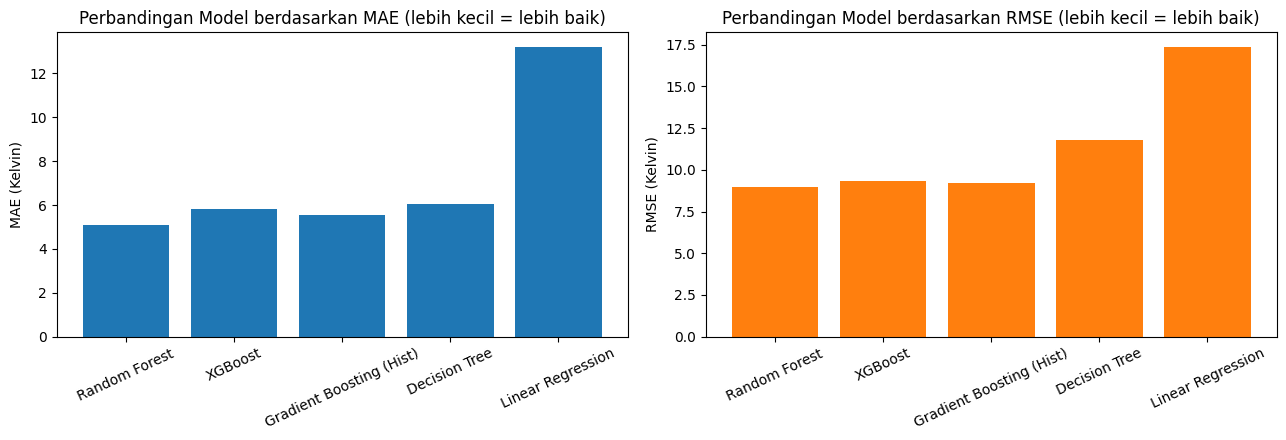

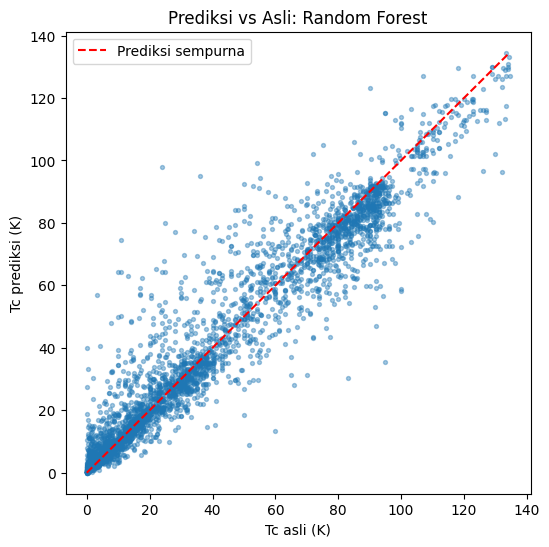

In [7]:
# Diagram batang perbandingan MAE dan RMSE
urut = hasil_df["Model"].tolist()
fig, sumbu = plt.subplots(1, 2, figsize=(13, 4.5))

sumbu[0].bar(urut, hasil_df["MAE"], color="tab:blue")
sumbu[0].set_ylabel("MAE (Kelvin)")
sumbu[0].set_title("Perbandingan Model berdasarkan MAE (lebih kecil = lebih baik)")

sumbu[1].bar(urut, hasil_df["RMSE"], color="tab:orange")
sumbu[1].set_ylabel("RMSE (Kelvin)")
sumbu[1].set_title("Perbandingan Model berdasarkan RMSE (lebih kecil = lebih baik)")

for s in sumbu:
    s.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# Prediksi vs nilai asli untuk model terbaik
y_pred_terbaik = model_terbaik.predict(x_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_terbaik, s=8, alpha=0.4)
batas = [0, max(y_test.max(), y_pred_terbaik.max())]
plt.plot(batas, batas, "r--", label="Prediksi sempurna")
plt.xlabel("Tc asli (K)")
plt.ylabel("Tc prediksi (K)")
plt.title(f"Prediksi vs Asli: {nama_terbaik}")
plt.legend()
plt.show()

## 7. Pentingnya Fitur (Feature Importance)

Random Forest dapat menunjukkan fitur mana yang paling banyak membantu prediksi. Pada data penuh, deskriptor terkait konduktivitas termal, massa atom, valensi, dan densitas umumnya berada di peringkat atas.

15 fitur terpenting menurut Random Forest:
range_ThermalConductivity          0.223958
wtd_std_ThermalConductivity        0.122298
wtd_entropy_Valence                0.064234
range_atomic_radius                0.052631
wtd_mean_Valence                   0.041143
std_ThermalConductivity            0.032844
wtd_gmean_Valence                  0.032678
wtd_gmean_ThermalConductivity      0.029551
wtd_entropy_atomic_mass            0.029284
wtd_std_ElectronAffinity           0.028754
wtd_mean_ThermalConductivity       0.021836
wtd_gmean_ElectronAffinity         0.020679
wtd_range_ElectronAffinity         0.018657
std_atomic_mass                    0.016696
wtd_entropy_ThermalConductivity    0.015072
dtype: float64


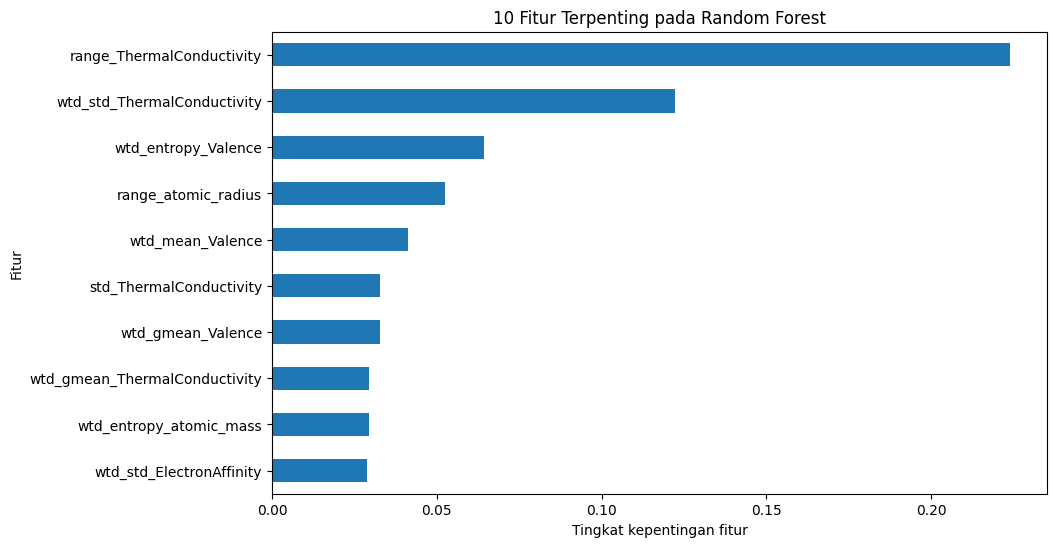

In [8]:
rf_model = model_terlatih["Random Forest"]
pentingnya_fitur = pd.Series(rf_model.feature_importances_, index=X.columns)
pentingnya_fitur = pentingnya_fitur.sort_values(ascending=False)

print("15 fitur terpenting menurut Random Forest:")
print(pentingnya_fitur.head(15))

fitur_teratas = pentingnya_fitur.head(10)
plt.figure(figsize=(10, 6))
fitur_teratas.plot(kind="barh")
plt.xlabel("Tingkat kepentingan fitur")
plt.ylabel("Fitur")
plt.title("10 Fitur Terpenting pada Random Forest")
plt.gca().invert_yaxis()   # fitur terpenting di paling atas
plt.show()

### Interpretasi Fitur Penting

Fitur dengan skor tinggi adalah yang paling berguna bagi model. Namun, **pentingnya fitur tidak membuktikan hubungan sebab-akibat fisika**. Ia hanya menunjukkan fitur mana yang paling membantu model memprediksi, dan fitur yang saling berkorelasi bisa saling "berbagi" skor.

## 8. Analisis Korelasi

Selain pentingnya fitur dari model, korelasi (Pearson) dengan `critical_temp` dihitung untuk melihat deskriptor mana yang paling berhubungan dengan target. Korelasi positif berarti nilai fitur yang tinggi cenderung bersama Tc yang tinggi, dan sebaliknya untuk korelasi negatif.

In [9]:
korelasi_target = df.corr(numeric_only=True)["critical_temp"].sort_values(ascending=False)

print("15 korelasi positif terkuat (baris pertama = target itu sendiri):")
print(korelasi_target.head(15))
print("\n15 korelasi negatif terkuat:")
print(korelasi_target.tail(15))

15 korelasi positif terkuat (baris pertama = target itu sendiri):
critical_temp                  1.000000
wtd_std_ThermalConductivity    0.721271
range_ThermalConductivity      0.687654
range_atomic_radius            0.653759
std_ThermalConductivity        0.653632
wtd_entropy_atomic_mass        0.626930
wtd_entropy_atomic_radius      0.603494
number_of_elements             0.601069
range_fie                      0.600790
wtd_std_atomic_radius          0.599199
entropy_Valence                0.598591
wtd_entropy_Valence            0.589664
wtd_std_fie                    0.582013
entropy_fie                    0.567817
wtd_entropy_FusionHeat         0.563244
Name: critical_temp, dtype: float64

15 korelasi negatif terkuat:
gmean_ElectronAffinity      -0.380568
mean_FusionHeat             -0.385509
gmean_ThermalConductivity   -0.387192
wtd_mean_FusionHeat         -0.394117
wtd_gmean_atomic_radius     -0.405176
gmean_FusionHeat            -0.431795
wtd_gmean_FusionHeat        -0.432365
wt

### Interpretasi Korelasi

Beberapa deskriptor terkait konduktivitas termal, jari-jari atom, dan jumlah unsur berkorelasi positif kuat dengan Tc. Deskriptor terkait valensi dan densitas cenderung berkorelasi negatif. Ini menunjukkan data mengandung struktur yang bermakna, bukan sekadar derau. Meski begitu, korelasi saja tidak membuktikan hubungan kausal fisika.

## 9. Distribusi Variabel Target

Histogram `critical_temp` dibuat untuk memahami sebaran target.

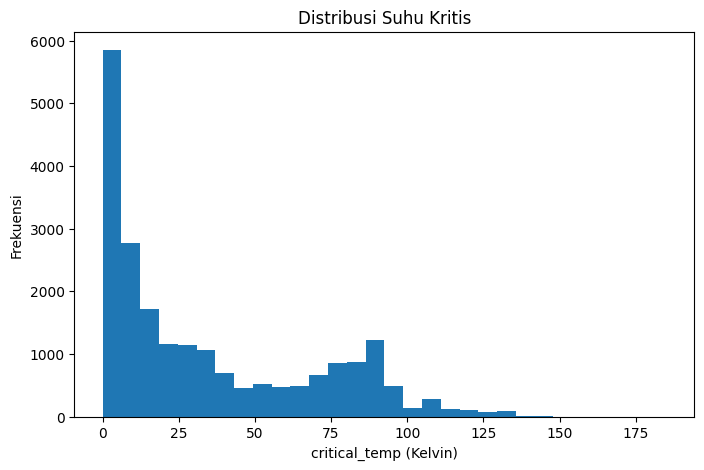

Rata-rata Tc : 34.42 K
Median Tc    : 20.00 K
Tc maksimum  : 185.00 K


In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df["critical_temp"], bins=30)
plt.xlabel("critical_temp (Kelvin)")
plt.ylabel("Frekuensi")
plt.title("Distribusi Suhu Kritis")
plt.show()

print(f"Rata-rata Tc : {df['critical_temp'].mean():.2f} K")
print(f"Median Tc    : {df['critical_temp'].median():.2f} K")
print(f"Tc maksimum  : {df['critical_temp'].max():.2f} K")

### Interpretasi Distribusi Target

Distribusi `critical_temp` tidak seragam. Kebanyakan material punya Tc relatif rendah dan hanya sedikit yang bernilai tinggi. Ini membuat tugas prediksi tidak sepele, dan data kemungkinan terdiri dari beberapa kelompok material atau rezim yang berbeda.

## 10. Visualisasi PCA

*Principal Component Analysis* (PCA) dipakai untuk mereduksi ruang fitur berdimensi tinggi menjadi dua dimensi agar bisa digambar. PCA tidak menggantikan fitur asli, tetapi membantu melihat apakah data memiliki struktur yang terlihat. Fitur distandarisasi terlebih dahulu karena PCA sensitif terhadap skala.

Bentuk hasil PCA: (21263, 2)
Varians yang dijelaskan per komponen: [0.3893 0.1048]
Total varians yang dijelaskan: 0.4941


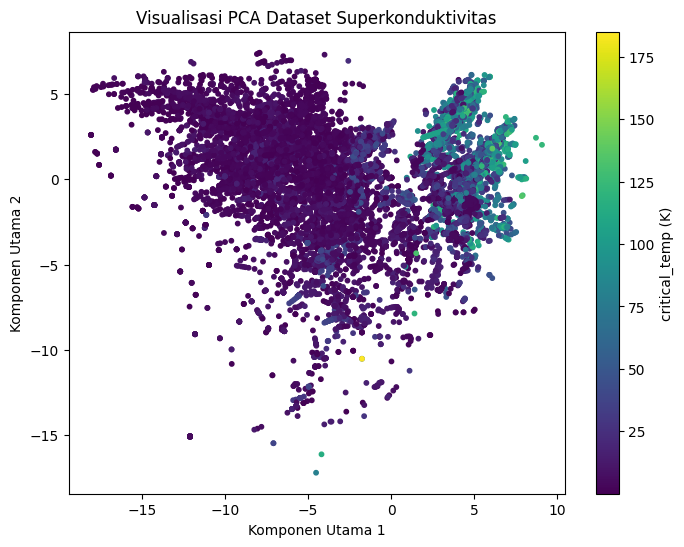

In [11]:
penskala = StandardScaler()
X_terskala = penskala.fit_transform(X)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_terskala)

print("Bentuk hasil PCA:", X_pca.shape)
print("Varians yang dijelaskan per komponen:", pca.explained_variance_ratio_.round(4))
print("Total varians yang dijelaskan:", round(pca.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(8, 6))
sebar = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y.values, s=10)
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.title("Visualisasi PCA Dataset Superkonduktivitas")
plt.colorbar(sebar, label="critical_temp (K)")
plt.show()

### Interpretasi PCA

Jika material ber-Tc tinggi cenderung mengelompok di area tertentu pada proyeksi dua dimensi, berarti deskriptor memuat informasi prediktif tentang `critical_temp`. Dua komponen pertama hanya menjelaskan sebagian varians total, jadi gambar ini adalah gambaran kasar, bukan bukti utuh.

## 11. Demo Input dan Output

Bagian ini menunjukkan cara memakai model yang sudah dilatih. Model terbaik dipakai untuk semua demo di bawah.

### Demo 1: Prediksi pada 5 sampel data uji

**Input:** 5 material acak dari data uji (fitur-fiturnya).
**Output:** Tc asli dibandingkan Tc prediksi.

In [12]:
# INPUT: ambil 5 material acak dari data uji
contoh = x_test.sample(5, random_state=SEED)

# PROSES: model memprediksi Tc dari fitur-fitur material
prediksi = model_terbaik.predict(contoh)

# OUTPUT: bandingkan dengan nilai asli
demo1 = pd.DataFrame({
    "Tc asli (K)": y_test.loc[contoh.index].round(2),
    "Tc prediksi (K)": prediksi.round(2),
})
demo1["Selisih (K)"] = (demo1["Tc prediksi (K)"] - demo1["Tc asli (K)"]).round(2)

print(f"Model yang dipakai: {nama_terbaik}")
display(demo1)
print(f"Rata-rata selisih absolut pada 5 sampel ini: {demo1['Selisih (K)'].abs().mean():.2f} K")

Model yang dipakai: Random Forest


,Tc asli (K),Tc prediksi (K),Selisih (K)
503,36.90,48.99,12.09
7387,37.00,67.02,30.02
4191,85.23,73.71,-11.52
19340,17.20,14.40,-2.80
17821,1.10,2.47,1.37


Rata-rata selisih absolut pada 5 sampel ini: 11.56 K


### Demo 2: Input manual (Anda yang mengisi fitur)

Model butuh semua fitur, tetapi Anda cukup mengisi fitur yang diketahui. Fitur lain otomatis diisi dengan **median data latih**. Fungsi `prediksi_tc()` juga mengecek bahwa nama fitur yang Anda ketik benar.

**Cara pakai:** ubah nilai pada `INPUT_SAYA`, lalu jalankan sel. Nama fitur yang valid bisa dilihat pada `X.columns`.

In [13]:
def prediksi_tc(input_fitur, model=None, dasar=None):
    """
    Memprediksi Tc (Kelvin) dari fitur yang diisi pengguna.

    input_fitur : dict {nama_fitur: nilai}, hanya fitur yang ingin diatur
    model       : model yang dipakai (default: model terbaik)
    dasar       : baris dasar (pd.Series) untuk fitur yang tidak diisi
                  (default: median data latih)
    """
    if model is None:
        model = model_terbaik
    baris = (x_train.median() if dasar is None else dasar).astype(float).copy()

    # Validasi nama fitur agar tidak diam-diam salah ketik
    salah = [k for k in input_fitur if k not in baris.index]
    if salah:
        raise ValueError(f"Nama fitur tidak dikenal: {salah}. Lihat daftar lengkap di X.columns")

    for nama, nilai in input_fitur.items():
        baris[nama] = float(nilai)

    X_baru = pd.DataFrame([baris.values], columns=x_train.columns)
    return float(model.predict(X_baru)[0])


# ======== UBAH NILAI DI BAWAH INI UNTUK MENCOBA ========
INPUT_SAYA = {
    "number_of_elements": 4,               # jumlah unsur penyusun material
    "range_ThermalConductivity": 350.0,    # rentang konduktivitas termal
    "wtd_std_ThermalConductivity": 100.0,  # simpangan baku berbobot konduktivitas termal
    "mean_Valence": 3.5,                   # rata-rata valensi
}
# =======================================================

tc = prediksi_tc(INPUT_SAYA)
print("INPUT :", INPUT_SAYA)
print(f"OUTPUT: Prediksi Tc = {tc:.1f} K  (sekitar {tc - 273.15:.1f} °C)")

# Konteks praktis: titik didih nitrogen cair = 77 K
if tc > 77:
    print("Kategori: di atas 77 K, bisa didinginkan dengan nitrogen cair yang murah (high-Tc).")
else:
    print("Kategori: di bawah 77 K, umumnya perlu pendinginan helium cair yang mahal (low-Tc).")

INPUT : {'number_of_elements': 4, 'range_ThermalConductivity': 350.0, 'wtd_std_ThermalConductivity': 100.0, 'mean_Valence': 3.5}
OUTPUT: Prediksi Tc = 22.8 K  (sekitar -250.3 °C)
Kategori: di bawah 77 K, umumnya perlu pendinginan helium cair yang mahal (low-Tc).


**Catatan penting:** pada Demo 2, fitur yang tidak diisi memakai median, sehingga kombinasi fiturnya mungkin tidak sesuai material nyata (antarfitur saling berkorelasi). Hasilnya cocok untuk memahami cara kerja model, bukan untuk menyimpulkan sebuah material. Pendekatan yang lebih realistis adalah memakai **baris material nyata sebagai dasar**, lalu mengubah satu-dua fitur (analisis "bagaimana jika"), seperti di bawah.

In [14]:
# Analisis "bagaimana jika": ambil satu material nyata dari data uji sebagai dasar,
# lalu ubah satu fitur dan lihat bagaimana prediksi Tc berubah.
material_dasar = x_test.iloc[0]
tc_asli = y_test.iloc[0]
print(f"Material dasar (indeks data uji 0): Tc asli = {tc_asli:.1f} K")
print(f"Prediksi tanpa perubahan : {prediksi_tc({}, dasar=material_dasar):.1f} K\n")

nilai_awal = material_dasar["range_ThermalConductivity"]
variasi = [nilai_awal * f for f in (0.25, 0.5, 1.0, 1.5, 2.0)]
tabel = pd.DataFrame({
    "range_ThermalConductivity": np.round(variasi, 1),
    "Tc prediksi (K)": [round(prediksi_tc({"range_ThermalConductivity": v}, dasar=material_dasar), 1)
                        for v in variasi],
})
display(tabel)

Material dasar (indeks data uji 0): Tc asli = 6.4 K
Prediksi tanpa perubahan : 11.6 K



,range_ThermalConductivity,Tc prediksi (K)
0,1.5,11.6
1,3.0,11.6
2,6.0,11.6
3,9.0,11.6
4,12.0,11.6


### Demo 3: Menyaring kandidat (peringkat Tc tertinggi)

Ini gambaran awal dari *pipeline* penyaringan pada motivasi proyek: model memprediksi Tc untuk banyak material, lalu kita mengurutkan kandidat dengan prediksi tertinggi untuk diprioritaskan pengujian di laboratorium.

**Input:** seluruh data uji. **Output:** 10 material dengan prediksi Tc tertinggi.

In [15]:
semua_prediksi = model_terbaik.predict(x_test)

peringkat = pd.DataFrame({
    "Tc prediksi (K)": semua_prediksi,
    "Tc asli (K)": y_test.values,
}, index=x_test.index)
peringkat["Selisih (K)"] = peringkat["Tc prediksi (K)"] - peringkat["Tc asli (K)"]

top10 = peringkat.sort_values("Tc prediksi (K)", ascending=False).head(10).round(2)
display(top10)

# Seberapa tepat penyaringan ini? Hitung berapa dari 10 kandidat yang Tc aslinya memang tinggi.
ambang = y_test.quantile(0.95)
tepat = (top10["Tc asli (K)"] >= ambang).sum()
print(f"{tepat} dari 10 kandidat teratas benar-benar termasuk 5% material ber-Tc tertinggi (Tc >= {ambang:.1f} K).")

,Tc prediksi (K),Tc asli (K),Selisih (K)
5477,134.44,133.40,1.04
5474,133.29,134.20,-0.91
4032,130.77,134.00,-3.23
3894,130.02,128.80,1.22
3682,129.94,129.00,0.94
4034,129.89,134.00,-4.11
4413,129.64,118.00,11.64
8591,129.58,132.52,-2.94
4031,129.28,134.00,-4.72
7068,129.07,133.00,-3.93


10 dari 10 kandidat teratas benar-benar termasuk 5% material ber-Tc tertinggi (Tc >= 94.0 K).


### Demo 4: Simpan dan muat model

Model yang sudah dilatih bisa disimpan ke file, lalu dimuat kembali tanpa melatih ulang. Berguna jika model akan dipakai di aplikasi lain.

In [16]:
NAMA_FILE_MODEL = "model_tc_terbaik.joblib"

# Simpan model dan daftar nama fitur (urutan fitur harus sama saat dipakai kembali)
joblib.dump({"model": model_terbaik, "fitur": list(X.columns), "nama": nama_terbaik},
            NAMA_FILE_MODEL, compress=3)
ukuran_mb = os.path.getsize(NAMA_FILE_MODEL) / 1e6
print(f"Model disimpan ke '{NAMA_FILE_MODEL}' ({ukuran_mb:.1f} MB)")

# Muat kembali dan buktikan hasilnya identik
paket = joblib.load(NAMA_FILE_MODEL)
model_dimuat = paket["model"]
sampel = x_test[paket["fitur"]].head(3)

pred_asli = model_terbaik.predict(sampel)
pred_muat = model_dimuat.predict(sampel)
print("Prediksi model asli  :", pred_asli.round(2))
print("Prediksi model dimuat:", pred_muat.round(2))
print("Identik:", np.allclose(pred_asli, pred_muat))

Model disimpan ke 'model_tc_terbaik.joblib' (28.3 MB)
Prediksi model asli  : [11.6  84.75 28.39]
Prediksi model dimuat: [11.6  84.75 28.39]
Identik: True


## 12. Ringkasan Otomatis

Sel berikut menulis ringkasan hasil berdasarkan angka dari eksekusi ini.

In [17]:
baris_terbaik = hasil_df.loc[0]
baris_terburuk = hasil_df.iloc[-1]
print(f"Model terbaik   : {baris_terbaik['Model']}  "
      f"(MAE = {baris_terbaik['MAE']:.2f} K, RMSE = {baris_terbaik['RMSE']:.2f} K, R2 = {baris_terbaik['R2']:.3f})")
print(f"Model terlemah  : {baris_terburuk['Model']}  "
      f"(MAE = {baris_terburuk['MAE']:.2f} K, RMSE = {baris_terburuk['RMSE']:.2f} K, R2 = {baris_terburuk['R2']:.3f})")
print(f"Fitur terpenting: {pentingnya_fitur.index[0]} (skor {pentingnya_fitur.iloc[0]:.3f})")
print(f"Total waktu pelatihan semua model: {hasil_df['Waktu (detik)'].sum():.0f} detik")

Model terbaik   : Random Forest  (MAE = 5.09 K, RMSE = 8.98 K, R2 = 0.930)
Model terlemah  : Linear Regression  (MAE = 13.21 K, RMSE = 17.38 K, R2 = 0.738)
Fitur terpenting: range_ThermalConductivity (skor 0.224)
Total waktu pelatihan semua model: 154 detik


## 13. Keterbatasan

- Dataset memakai deskriptor hasil rekayasa fitur, bukan pengukuran fisika eksperimen langsung.
- Sebagian baris memerlukan pembersihan karena masalah format pada file CSV.
- Pentingnya fitur dan korelasi tidak membuktikan hubungan sebab-akibat fisika.
- PCA adalah alat visualisasi dan tidak memberi interpretasi fisika langsung.
- Evaluasi memakai satu pembagian latih-uji dan *cross-validation* pada data latih. Satu rumus kimia bisa muncul dengan variasi di data, sehingga ada risiko kebocoran antarsampel mirip yang membuat skor tampak lebih baik daripada kenyataan pada material yang benar-benar baru.
- Demo input manual memakai median untuk fitur yang tidak diisi, sehingga kombinasi fiturnya belum tentu realistis.
- Model tidak memberi estimasi ketidakpastian pada setiap prediksi.

Oleh karena itu, hasil ini sebaiknya dianggap sebagai **bukti konsep (*proof of concept*)**, bukan kesimpulan ilmiah akhir.

## 14. Pengembangan Selanjutnya

- Menguji dataset superkonduktivitas tambahan.
- Menggabungkan deskriptor hasil rekayasa dengan pengukuran fisika yang lebih langsung.
- Memakai pembagian data yang dikelompokkan per keluarga material (*group split*) agar evaluasi lebih jujur.
- Menyetel hiperparameter secara sistematis (misalnya `RandomizedSearchCV` atau Optuna).
- Membangun *pipeline* peringkat untuk menyaring kandidat superkonduktor yang menjanjikan.
- Menambahkan estimasi ketidakpastian pada prediksi (misalnya *quantile regression* atau *conformal prediction*).

## 15. Kesimpulan

Proyek ini menunjukkan bahwa model *machine learning* dapat memprediksi suhu kritis superkonduktor dari deskriptor material dengan akurasi yang berarti. Model berbasis pohon dan *ensemble* umumnya unggul atas regresi linier, yang menandakan hubungan antara deskriptor dan Tc sangat nonlinier. Pentingnya fitur, korelasi, dan PCA memperlihatkan bahwa dataset memuat struktur yang relevan untuk prediksi.

Secara keseluruhan, ini adalah *pipeline* ML awal untuk penyaringan superkonduktor, yang menjadi fondasi untuk alur kerja penemuan material yang lebih lanjut.